# 05. Comprehensive Evaluation, Calibration & Safety Trade-offs
### Side-by-Side Benchmarking, ECE Calibration & Risk-Sensitive Abstention
**Course:** Applied Machine Learning & Deep Learning (AML-DL)

---
## 1. Master Model Comparison
We evaluate all models side-by-side on our strictly held-out, deduplicated test set (378 images).


In [1]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REPO_ROOT = Path("..").resolve()
METRICS_DIR = REPO_ROOT / "results" / "metrics"
FIGURES_DIR = REPO_ROOT / "results" / "figures"

master_df = pd.read_csv(METRICS_DIR / "master_model_comparison.csv")
display(master_df)


,Model,Test_Accuracy,Macro_F1,Macro_Precision,Macro_Recall,ECE,Abstain_Rate_tau_0_60,Retained_Accuracy_tau_0_60
0,SVM (RBF Kernel),73.28,0.7199,0.7304,0.7133,0.0590,38.36,89.27
1,Random Forest,74.87,0.7405,0.7804,0.7204,0.3168,83.33,98.41
2,MobileNetV2,84.39,0.8268,0.8243,0.8303,0.1038,26.46,94.60


## 2. Per-Class Recall Gains: Where Deep Learning Wins
Examining where MobileNetV2 overcomes the physical limitations of hand-crafted descriptors.


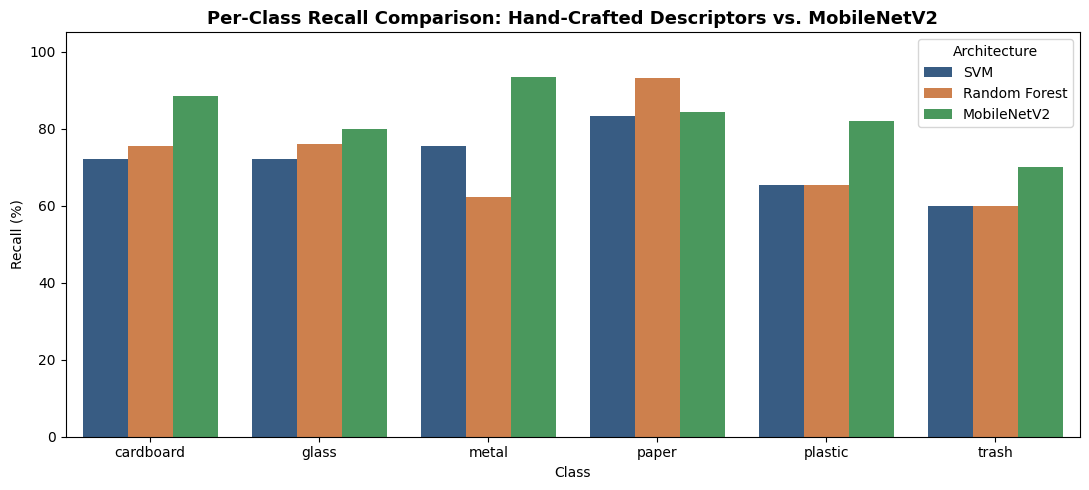

In [2]:
per_class_df = pd.read_csv(METRICS_DIR / "per_class_performance.csv")

plt.figure(figsize=(11, 5))
sns.barplot(data=per_class_df, x="Class", y="Recall", hue="Model", palette=["#2b5c8f", "#e27c38", "#3da556"])
plt.title("Per-Class Recall Comparison: Hand-Crafted Descriptors vs. MobileNetV2", fontsize=13, fontweight="bold")
plt.ylabel("Recall (%)")
plt.ylim(0, 105)
plt.legend(title="Architecture")
plt.tight_layout()
plt.show()


## 3. Reliability & Calibration Analysis (ECE)
Examining whether predicted softmax confidence accurately estimates the empirical probability of correct classification.


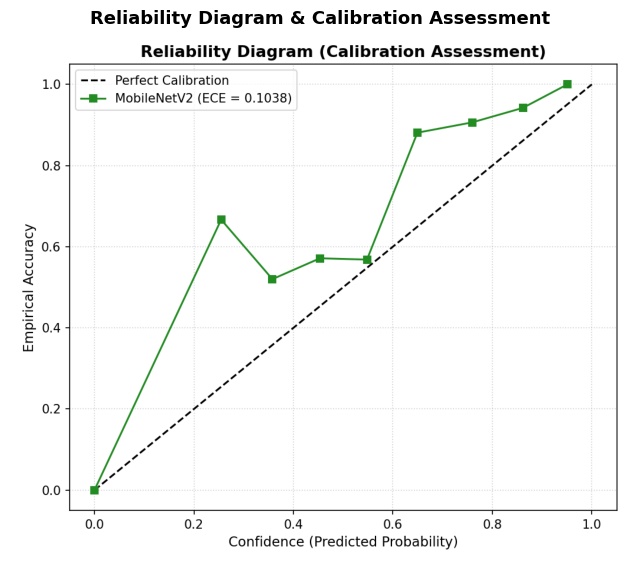

In [3]:
from PIL import Image

calib_fig = Image.open(FIGURES_DIR / "calibration_curve.png")
plt.figure(figsize=(8, 7))
plt.imshow(calib_fig)
plt.axis("off")
plt.title("Reliability Diagram & Calibration Assessment", fontsize=13, fontweight="bold")
plt.show()


## 4. The Confidence-Abstain Trade-Off (Selective Classification)
How varying the safety threshold $	au$ enables near-zero contamination at acceptable coverage levels.


,Threshold_Tau,SVM_Abstain_Pct,SVM_Retained_Accuracy,DL_Abstain_Pct,DL_Retained_Accuracy
0,0.10,0.00,73.28,0.00,84.39
1,0.15,0.00,73.28,0.00,84.39
2,0.20,0.00,73.28,0.00,84.39
3,0.25,0.00,73.28,0.53,84.31
4,0.30,2.65,74.73,0.79,84.53
5,0.35,7.94,77.30,3.17,85.52
6,0.40,15.08,79.75,7.41,86.86
7,0.45,21.69,82.43,10.58,88.17
8,0.50,28.31,84.50,14.81,89.44
9,0.55,34.39,87.90,21.16,92.62


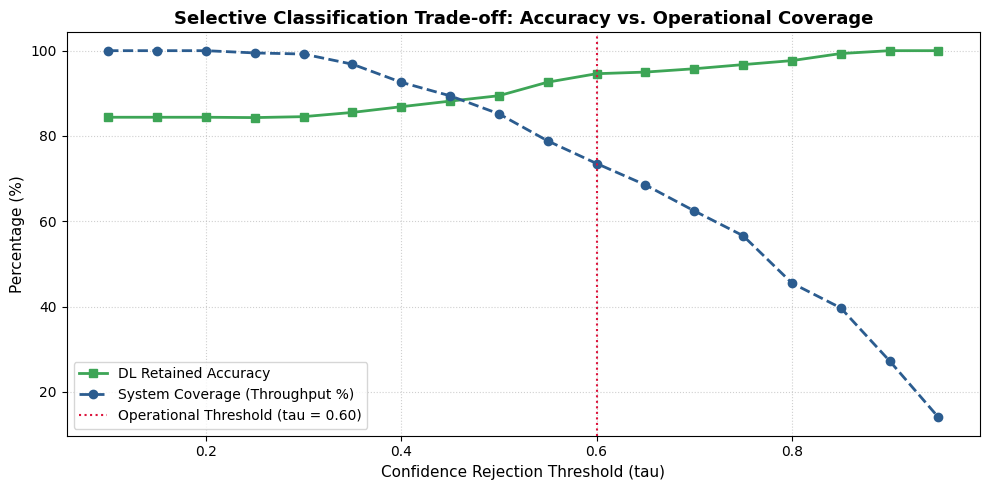

In [4]:
sweep_df = pd.read_csv(METRICS_DIR / "abstain_threshold_sweep.csv")
display(sweep_df.head(10))

plt.figure(figsize=(10, 5))
plt.plot(sweep_df["Threshold_Tau"], sweep_df["DL_Retained_Accuracy"], "s-", color="#3da556", label="DL Retained Accuracy", linewidth=2)
plt.plot(sweep_df["Threshold_Tau"], 100 - sweep_df["DL_Abstain_Pct"], "o--", color="#2b5c8f", label="System Coverage (Throughput %)", linewidth=2)
plt.axvline(0.60, color="crimson", linestyle=":", label="Operational Threshold (tau = 0.60)")

plt.xlabel("Confidence Rejection Threshold (tau)", fontsize=11)
plt.ylabel("Percentage (%)", fontsize=11)
plt.title("Selective Classification Trade-off: Accuracy vs. Operational Coverage", fontsize=13, fontweight="bold")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


## 5. Qualitative Failure Case Analysis
Displaying the visual failure cases where HOG and LBP broke down on deformed/crumpled items while MobileNetV2 succeeded.


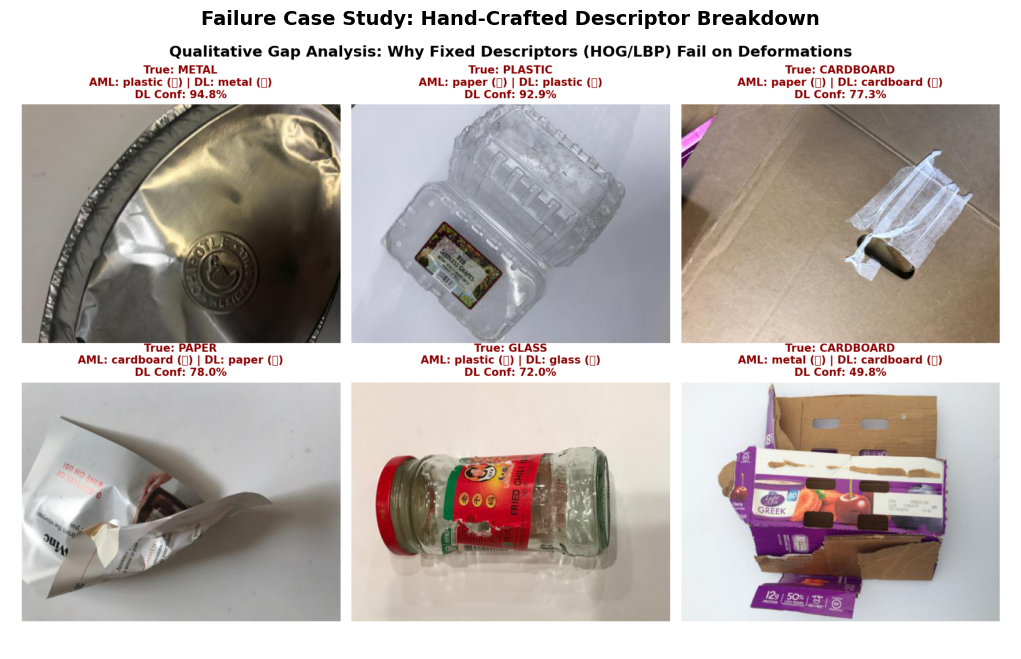

In [5]:
fail_cases_fig = Image.open(FIGURES_DIR / "failure_cases_aml_vs_dl.png")
plt.figure(figsize=(13, 8))
plt.imshow(fail_cases_fig)
plt.axis("off")
plt.title("Failure Case Study: Hand-Crafted Descriptor Breakdown", fontsize=14, fontweight="bold")
plt.show()
